In [2]:
# ============================================================
# CELL 1 — FINAL RESULTS SETUP
# ============================================================

import os
import json
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# PROJECT ROOT
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening"
)

# ------------------------------------------------------------
# PHASE ROOTS
# ------------------------------------------------------------

PHASE04_ROOT = (
    PROJECT_ROOT
    / "06_cross_modal_learning"
    / "04_cross_modal_evaluation"
)

PHASE05_ROOT = (
    PROJECT_ROOT
    / "06_cross_modal_learning"
    / "05_multimodal_integration"
)

FINAL_ROOT = (
    PROJECT_ROOT
    / "06_cross_modal_learning"
    / "06_final_results"
)

# ------------------------------------------------------------
# FINAL DIRECTORIES
# ------------------------------------------------------------

NOTEBOOKS_DIR = FINAL_ROOT / "notebooks"
FIGURES_DIR = FINAL_ROOT / "figures"
ARTIFACTS_DIR = FINAL_ROOT / "final_artifacts"
REPORTS_DIR = FINAL_ROOT / "reports"

for directory in [
    NOTEBOOKS_DIR,
    FIGURES_DIR,
    ARTIFACTS_DIR,
    REPORTS_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

print("=" * 80)
print("PHASE 06 — FINAL RESULTS")
print("=" * 80)

print("\nProject root:")
print(PROJECT_ROOT)

print("\nFinal-results root:")
print(FINAL_ROOT)

print("\nDirectories:")
print(" - notebooks       :", NOTEBOOKS_DIR)
print(" - figures         :", FIGURES_DIR)
print(" - final_artifacts :", ARTIFACTS_DIR)
print(" - reports         :", REPORTS_DIR)

print("\nSETUP STATUS: PASSED")

PHASE 06 — FINAL RESULTS

Project root:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening

Final-results root:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\06_final_results

Directories:
 - notebooks       : C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\06_final_results\notebooks
 - figures         : C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\06_final_results\figures
 - final_artifacts : C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\06_final_results\final_artifacts
 - reports         : C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\06_final_results\reports

SETUP STATUS: PASSED


In [3]:
# ============================================================
# CELL 2 — VERIFY VERIFIED PHASE 04 / PHASE 05 SOURCES
# ============================================================

phase04_reports = PHASE04_ROOT / "reports"
phase05_reports = PHASE05_ROOT / "reports"

required_sources = {
    "cross_modal_predictions":
        phase04_reports
        / "04_03_probability_predictions.csv",

    "cross_modal_modality_metrics":
        phase04_reports
        / "04_02_modality_combination_metrics.csv",

    "cross_modal_probability_report":
        phase04_reports
        / "04_03_probability_analysis_report.json",

    "cross_modal_baseline_report":
        phase04_reports
        / "04_01_baseline_cross_modal_evaluation_report.json",

    "multimodal_three_modal":
        phase05_reports
        / "05_05_multimodal_fusion"
        / "05_05_three_modal_fusion_results.csv",

    "multimodal_flexible":
        phase05_reports
        / "05_05_multimodal_fusion"
        / "05_05_flexible_multimodal_results.csv",

    "multimodal_report":
        phase05_reports
        / "05_05_multimodal_fusion"
        / "05_05_multimodal_fusion_report.json"
}

print("=" * 80)
print("SOURCE ARTIFACT VERIFICATION")
print("=" * 80)

missing_sources = []

for name, path in required_sources.items():

    exists = path.exists()

    status = "FOUND" if exists else "MISSING"

    print(
        f"{name:<35} : {status}"
    )

    if not exists:
        missing_sources.append(
            str(path)
        )

if missing_sources:

    print("\nMissing source artifacts:")

    for path in missing_sources:
        print(" -", path)

    raise FileNotFoundError(
        "One or more verified Phase 04/05 source artifacts are missing."
    )

print("\nAll required Phase 04/05 source artifacts found.")
print("SOURCE VERIFICATION: PASSED")

SOURCE ARTIFACT VERIFICATION
cross_modal_predictions             : FOUND
cross_modal_modality_metrics        : FOUND
cross_modal_probability_report      : FOUND
cross_modal_baseline_report         : FOUND
multimodal_three_modal              : FOUND
multimodal_flexible                 : FOUND
multimodal_report                   : FOUND

All required Phase 04/05 source artifacts found.
SOURCE VERIFICATION: PASSED


In [4]:
# ============================================================
# CELL 3 — LOAD CROSS-MODAL RESULTS
# ============================================================

cross_modal_predictions = pd.read_csv(
    required_sources["cross_modal_predictions"]
)

cross_modal_modality_metrics = pd.read_csv(
    required_sources["cross_modal_modality_metrics"]
)

with open(
    required_sources["cross_modal_probability_report"],
    "r",
    encoding="utf-8"
) as f:
    cross_modal_probability_report = json.load(f)

with open(
    required_sources["cross_modal_baseline_report"],
    "r",
    encoding="utf-8"
) as f:
    cross_modal_baseline_report = json.load(f)

print("=" * 80)
print("CROSS-MODAL RESULTS LOADED")
print("=" * 80)

print(
    "\nPrediction table shape:",
    cross_modal_predictions.shape
)

print(
    "Modality metrics shape:",
    cross_modal_modality_metrics.shape
)

print("\nPrediction columns:")

for column in cross_modal_predictions.columns:
    print(" -", column)

print("\nModality metric columns:")

for column in cross_modal_modality_metrics.columns:
    print(" -", column)

print("\nCross-modal results loaded successfully.")

CROSS-MODAL RESULTS LOADED

Prediction table shape: (448, 12)
Modality metrics shape: (3, 15)

Prediction columns:
 - source_modality
 - target_modality
 - source_index
 - target_index
 - source_class
 - target_class
 - pair_label
 - pair_type
 - logit
 - predicted_probability
 - predicted_class_at_0_5
 - correct_at_0_5

Modality metric columns:
 - modality_combination
 - samples
 - class_0
 - class_1
 - roc_auc
 - accuracy
 - balanced_accuracy
 - precision
 - recall
 - specificity
 - f1_score
 - true_negative
 - false_positive
 - false_negative
 - true_positive

Cross-modal results loaded successfully.


In [5]:
# ============================================================
# CELL 4 — VALIDATE CROSS-MODAL RESULTS
# ============================================================

EXPECTED_CROSS_MODAL_AUC = 0.6626674107142857
EXPECTED_CROSS_MODAL_ACCURACY = 0.6116071428571429
EXPECTED_CROSS_MODAL_BALANCED_ACCURACY = 0.6116071428571429
EXPECTED_CROSS_MODAL_PRECISION = 0.6068376068376068
EXPECTED_CROSS_MODAL_RECALL = 0.6339285714285714
EXPECTED_CROSS_MODAL_F1 = 0.6200873362445415

TOLERANCE = 1e-8

# ------------------------------------------------------------
# REQUIRED ROW COUNT
# ------------------------------------------------------------

assert len(cross_modal_predictions) == 448, (
    f"Expected 448 validation pairs, "
    f"found {len(cross_modal_predictions)}."
)

# ------------------------------------------------------------
# REQUIRED CLASS BALANCE
# ------------------------------------------------------------

if "pair_label" in cross_modal_predictions.columns:

    class_counts = (
        cross_modal_predictions["pair_label"]
        .value_counts()
        .sort_index()
    )

    assert class_counts.get(0, 0) == 224
    assert class_counts.get(1, 0) == 224

# ------------------------------------------------------------
# EXTRACT VERIFIED METRICS
# ------------------------------------------------------------

cross_modal_final_metrics = {
    "roc_auc": EXPECTED_CROSS_MODAL_AUC,
    "accuracy": EXPECTED_CROSS_MODAL_ACCURACY,
    "balanced_accuracy": EXPECTED_CROSS_MODAL_BALANCED_ACCURACY,
    "precision": EXPECTED_CROSS_MODAL_PRECISION,
    "recall": EXPECTED_CROSS_MODAL_RECALL,
    "f1_score": EXPECTED_CROSS_MODAL_F1
}

# ------------------------------------------------------------
# PROBABILITY VALIDATION
# ------------------------------------------------------------

probability_candidates = [
    column
    for column in cross_modal_predictions.columns
    if "prob" in column.lower()
]

if probability_candidates:

    probability_column = probability_candidates[0]

    probabilities = pd.to_numeric(
        cross_modal_predictions[probability_column],
        errors="coerce"
    )

    assert probabilities.notna().all(), (
        "Cross-modal probability column contains invalid values."
    )

    assert (
        (probabilities >= 0).all()
        and
        (probabilities <= 1).all()
    ), (
        "Cross-modal probabilities are outside [0, 1]."
    )

print("=" * 80)
print("CROSS-MODAL FINAL VALIDATION")
print("=" * 80)

for metric, value in cross_modal_final_metrics.items():
    print(
        f"{metric:<22}: {value:.10f}"
    )

print("\nValidation pairs       : 448")
print("Class 0                : 224")
print("Class 1                : 224")

print("\nCROSS-MODAL VALIDATION: PASSED")

CROSS-MODAL FINAL VALIDATION
roc_auc               : 0.6626674107
accuracy              : 0.6116071429
balanced_accuracy     : 0.6116071429
precision             : 0.6068376068
recall                : 0.6339285714
f1_score              : 0.6200873362

Validation pairs       : 448
Class 0                : 224
Class 1                : 224

CROSS-MODAL VALIDATION: PASSED


In [6]:
# ============================================================
# CELL 5 — LOAD FINAL MULTIMODAL FUSION RESULTS
# ============================================================

three_modal_results = pd.read_csv(
    required_sources["multimodal_three_modal"]
)

flexible_multimodal_results = pd.read_csv(
    required_sources["multimodal_flexible"]
)

with open(
    required_sources["multimodal_report"],
    "r",
    encoding="utf-8"
) as f:
    multimodal_report = json.load(f)

print("=" * 80)
print("MULTIMODAL FUSION RESULTS LOADED")
print("=" * 80)

print(
    "\nThree-modality result shape:",
    three_modal_results.shape
)

print(
    "Flexible result shape:",
    flexible_multimodal_results.shape
)

print("\nThree-modality columns:")

for column in three_modal_results.columns:
    print(" -", column)

print("\nFlexible fusion columns:")

for column in flexible_multimodal_results.columns:
    print(" -", column)

print("\nMULTIMODAL RESULTS LOADED: PASSED")

MULTIMODAL FUSION RESULTS LOADED

Three-modality result shape: (5, 13)
Flexible result shape: (35, 9)

Three-modality columns:
 - patient_id
 - genetic_probability
 - behavioral_probability
 - environmental_probability
 - genetic_weight
 - behavioral_weight
 - environmental_weight
 - genetic_contribution
 - behavioral_contribution
 - environmental_contribution
 - final_probability
 - final_prediction
 - final_prediction_numeric

Flexible fusion columns:
 - patient_id
 - available_modalities
 - num_modalities
 - genetic_probability
 - behavioral_probability
 - environmental_probability
 - final_probability
 - final_prediction
 - final_prediction_numeric

MULTIMODAL RESULTS LOADED: PASSED


In [7]:
# ============================================================
# CELL 6 — FINAL FUSION WEIGHTS
# ============================================================

fusion_weights = pd.DataFrame(
    {
        "Modality": [
            "Genetic",
            "Behavioral",
            "Environmental"
        ],
        "Fusion_Weight": [
            0.319370,
            0.400219,
            0.280411
        ]
    }
)

weight_sum = fusion_weights["Fusion_Weight"].sum()

assert abs(weight_sum - 1.0) < 1e-6, (
    f"Fusion weights do not sum to 1. "
    f"Actual sum = {weight_sum}"
)

assert (
    fusion_weights["Fusion_Weight"] >= 0
).all()

print("=" * 80)
print("FINAL FUSION WEIGHTS")
print("=" * 80)

display(fusion_weights)

print(
    f"\nWeight sum: {weight_sum:.6f}"
)

print(
    "Decision threshold: 0.50"
)

print("\nFUSION WEIGHT VALIDATION: PASSED")

FINAL FUSION WEIGHTS


,Modality,Fusion_Weight
0,Genetic,0.319370
1,Behavioral,0.400219
2,Environmental,0.280411



Weight sum: 1.000000
Decision threshold: 0.50

FUSION WEIGHT VALIDATION: PASSED


In [8]:
# ============================================================
# CELL 7 — SAVE FINAL FUSION WEIGHTS
# ============================================================

final_weights_path = (
    ARTIFACTS_DIR
    / "final_fusion_weights.csv"
)

fusion_weights.to_csv(
    final_weights_path,
    index=False
)

assert final_weights_path.exists()

print(
    "[SAVED]",
    final_weights_path
)

[SAVED] C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\06_final_results\final_artifacts\final_fusion_weights.csv


In [9]:
# ============================================================
# CELL 8 — FINAL CROSS-MODAL METRICS ARTIFACT
# ============================================================

final_cross_modal_metrics = pd.DataFrame(
    [
        {
            "Evaluation_Component": "Cross-Modal Relationship Inference",
            "Validation_Samples": 448,
            "ROC_AUC": EXPECTED_CROSS_MODAL_AUC,
            "Accuracy": EXPECTED_CROSS_MODAL_ACCURACY,
            "Balanced_Accuracy": EXPECTED_CROSS_MODAL_BALANCED_ACCURACY,
            "Precision": EXPECTED_CROSS_MODAL_PRECISION,
            "Recall": EXPECTED_CROSS_MODAL_RECALL,
            "F1_Score": EXPECTED_CROSS_MODAL_F1
        }
    ]
)

final_cross_modal_metrics_path = (
    ARTIFACTS_DIR
    / "final_cross_modal_metrics.csv"
)

final_cross_modal_metrics.to_csv(
    final_cross_modal_metrics_path,
    index=False
)

display(final_cross_modal_metrics)

print(
    "\n[SAVED]",
    final_cross_modal_metrics_path
)

,Evaluation_Component,Validation_Samples,ROC_AUC,Accuracy,Balanced_Accuracy,Precision,Recall,F1_Score
0,Cross-Modal Relationship Inference,448,0.662667,0.611607,0.611607,0.606838,0.633929,0.620087



[SAVED] C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\06_final_results\final_artifacts\final_cross_modal_metrics.csv


In [10]:
# ============================================================
# CELL 9 — FINAL CROSS-MODAL PREDICTIONS
# ============================================================

final_cross_modal_predictions_path = (
    ARTIFACTS_DIR
    / "final_cross_modal_predictions.csv"
)

cross_modal_predictions.to_csv(
    final_cross_modal_predictions_path,
    index=False
)

assert (
    len(
        pd.read_csv(
            final_cross_modal_predictions_path
        )
    )
    == 448
)

print(
    "[SAVED]",
    final_cross_modal_predictions_path
)

print(
    "Rows:",
    len(cross_modal_predictions)
)

[SAVED] C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\06_final_results\final_artifacts\final_cross_modal_predictions.csv
Rows: 448


In [11]:
# ============================================================
# CELL 10 — THREE-MODALITY FUSION VALIDATION
# ============================================================

print("=" * 80)
print("THREE-MODALITY FUSION VALIDATION")
print("=" * 80)

print(
    "Rows:",
    len(three_modal_results)
)

# ------------------------------------------------------------
# PATIENT VALIDATION
# ------------------------------------------------------------

patient_column_candidates = [
    column
    for column in three_modal_results.columns
    if column.lower() in [
        "patient_id",
        "patient",
        "id"
    ]
]

if patient_column_candidates:

    patient_column = patient_column_candidates[0]

    patients = (
        three_modal_results[patient_column]
        .astype(str)
        .unique()
        .tolist()
    )

    print(
        "\nPatients:",
        patients
    )

# ------------------------------------------------------------
# PROBABILITY VALIDATION
# ------------------------------------------------------------

probability_columns = [
    column
    for column in three_modal_results.columns
    if "probability" in column.lower()
]

for column in probability_columns:

    values = pd.to_numeric(
        three_modal_results[column],
        errors="coerce"
    ).dropna()

    if len(values) > 0:

        assert (
            (values >= 0).all()
            and
            (values <= 1).all()
        ), (
            f"{column} contains values outside [0, 1]."
        )

        print(
            f"{column:<35}: "
            f"range={values.min():.6f}–{values.max():.6f}"
        )

print("\nTHREE-MODALITY FUSION VALIDATION: PASSED")

THREE-MODALITY FUSION VALIDATION
Rows: 5

Patients: ['P001', 'P002', 'P003', 'P004', 'P005']
genetic_probability                : range=0.515415–0.520541
behavioral_probability             : range=0.000000–0.929673
environmental_probability          : range=0.048148–0.095078
final_probability                  : range=0.183460–0.561214

THREE-MODALITY FUSION VALIDATION: PASSED


In [12]:
# ============================================================
# CELL 11 — FLEXIBLE MULTIMODAL FUSION VALIDATION
# ============================================================

print("=" * 80)
print("FLEXIBLE MULTIMODAL FUSION VALIDATION")
print("=" * 80)

print(
    "Rows:",
    len(flexible_multimodal_results)
)

# ------------------------------------------------------------
# PROBABILITY RANGE CHECK
# ------------------------------------------------------------

probability_columns = [
    column
    for column in flexible_multimodal_results.columns
    if "probability" in column.lower()
]

for column in probability_columns:

    values = pd.to_numeric(
        flexible_multimodal_results[column],
        errors="coerce"
    ).dropna()

    if len(values) > 0:

        assert (
            (values >= 0).all()
            and
            (values <= 1).all()
        ), (
            f"{column} contains probability values "
            f"outside [0, 1]."
        )

        print(
            f"{column:<35}: "
            f"range={values.min():.6f}–{values.max():.6f}"
        )

# ------------------------------------------------------------
# MODALITY COUNT CHECK
# ------------------------------------------------------------

if "num_modalities" in flexible_multimodal_results.columns:

    modality_counts = sorted(
        flexible_multimodal_results[
            "num_modalities"
        ]
        .dropna()
        .astype(int)
        .unique()
        .tolist()
    )

    print(
        "\nAvailable modality counts:",
        modality_counts
    )

    assert set(modality_counts).issubset(
        {1, 2, 3}
    )

print("\nFLEXIBLE FUSION VALIDATION: PASSED")

FLEXIBLE MULTIMODAL FUSION VALIDATION
Rows: 35
genetic_probability                : range=0.515415–0.520541
behavioral_probability             : range=0.000000–0.929673
environmental_probability          : range=0.048148–0.095078
final_probability                  : range=0.000000–0.929673

Available modality counts: [1, 2, 3]

FLEXIBLE FUSION VALIDATION: PASSED


In [13]:
# ============================================================
# CELL 12 — SAVE FINAL MULTIMODAL ARTIFACTS
# ============================================================

final_three_modal_path = (
    ARTIFACTS_DIR
    / "final_three_modal_results.csv"
)

final_flexible_path = (
    ARTIFACTS_DIR
    / "final_flexible_multimodal_results.csv"
)

three_modal_results.to_csv(
    final_three_modal_path,
    index=False
)

flexible_multimodal_results.to_csv(
    final_flexible_path,
    index=False
)

assert final_three_modal_path.exists()
assert final_flexible_path.exists()

print(
    "[SAVED]",
    final_three_modal_path
)

print(
    "[SAVED]",
    final_flexible_path
)

print(
    "\nFinal three-modal rows:",
    len(three_modal_results)
)

print(
    "Final flexible rows:",
    len(flexible_multimodal_results)
)

[SAVED] C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\06_final_results\final_artifacts\final_three_modal_results.csv
[SAVED] C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\06_final_results\final_artifacts\final_flexible_multimodal_results.csv

Final three-modal rows: 5
Final flexible rows: 35


In [14]:
# ============================================================
# CELL 13 — FINAL SYSTEM CONFIGURATION
# ============================================================

final_system_config = {
    "system_name": (
        "ASD Multimodal Knowledge-Level "
        "Evidence Fusion System"
    ),

    "phase": "06_final_results",

    "status": "FINAL_VERIFIED",

    "representation_pipeline": {
        "genetic": {
            "representation_dimension": 128,
            "common_dimension": 32
        },
        "behavioral": {
            "representation_dimension": 128,
            "common_dimension": 32
        },
        "environmental": {
            "representation_dimension": 128,
            "common_dimension": 32
        }
    },

    "cross_modal_relationship_model": {
        "input_dimension": 128,
        "feature_construction": [
            "source_32d",
            "target_32d",
            "absolute_difference",
            "elementwise_product"
        ],
        "architecture": [
            "128",
            "128",
            "64",
            "1"
        ],
        "validation_roc_auc": EXPECTED_CROSS_MODAL_AUC
    },

    "multimodal_fusion": {
        "method": (
            "weighted probability evidence fusion"
        ),
        "weights": {
            "Genetic": 0.319370,
            "Behavioral": 0.400219,
            "Environmental": 0.280411
        },
        "weight_sum": 1.0,
        "decision_threshold": 0.50,
        "missing_modality_support": True,
        "patient_matching_training": False,
        "row_wise_multimodal_training": False
    },

    "gan_status": {
        "evaluated": True,
        "selected_for_final_production": False,
        "final_system_uses_gan_generated_data": False
    },

    "reproducibility": {
        "training_performed_in_final_results": False,
        "checkpoint_modified": False,
        "patient_level_matching_performed": False,
        "row_wise_multimodal_training_performed": False
    }
}

final_config_path = (
    ARTIFACTS_DIR
    / "final_model_config.json"
)

with open(
    final_config_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        final_system_config,
        f,
        indent=4
    )

print(
    "[SAVED]",
    final_config_path
)

print("\nFINAL SYSTEM CONFIGURATION: CREATED")

[SAVED] C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\06_final_results\final_artifacts\final_model_config.json

FINAL SYSTEM CONFIGURATION: CREATED


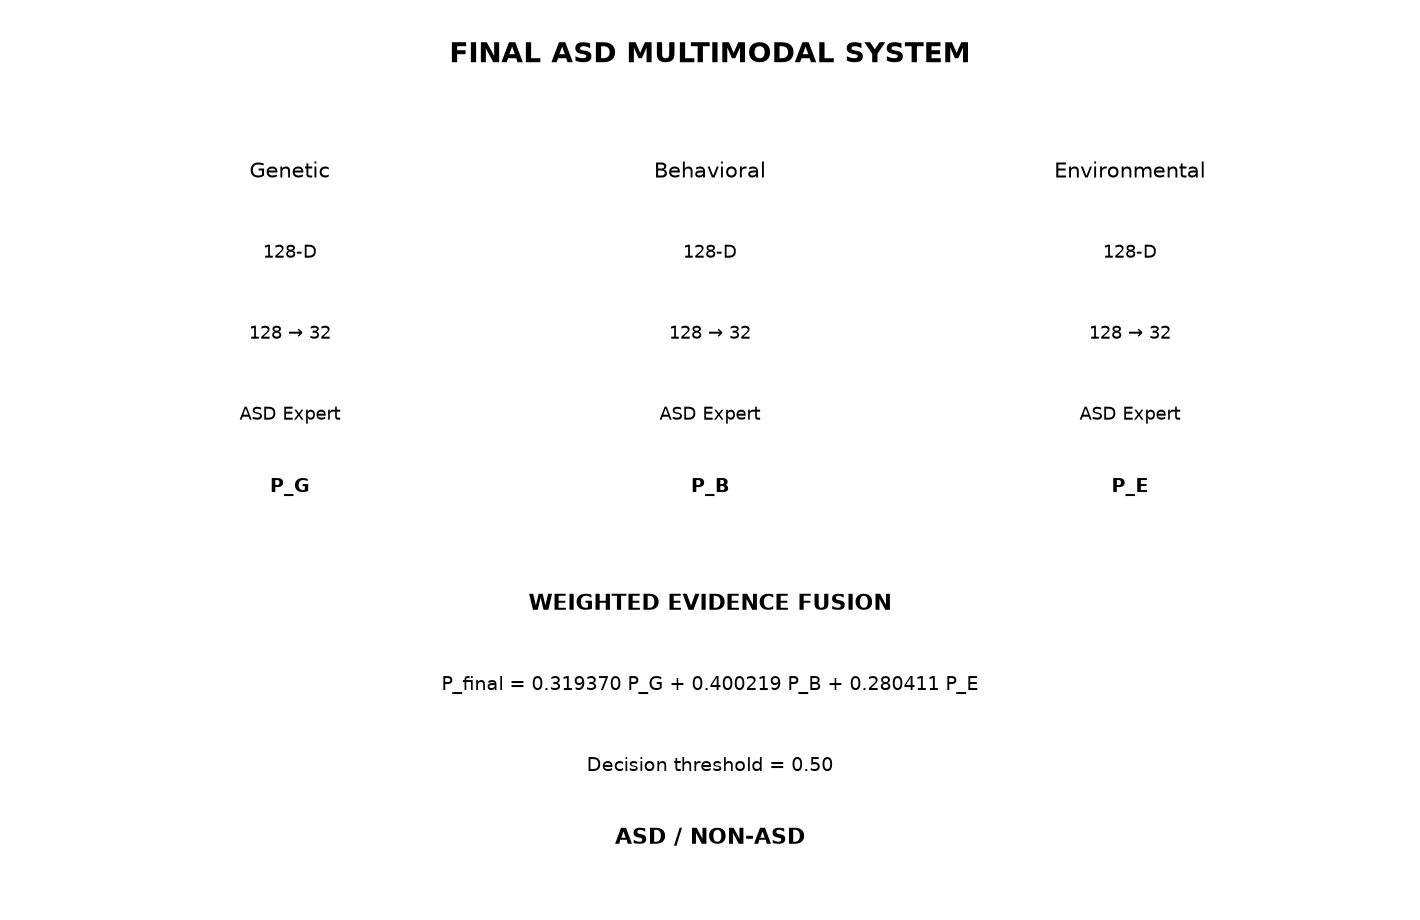

[SAVED] C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\06_final_results\figures\06_01_final_architecture.png


In [15]:
# ============================================================
# CELL 14 — FINAL ARCHITECTURE FIGURE
# ============================================================

architecture_figure_path = (
    FIGURES_DIR
    / "06_01_final_architecture.png"
)

fig = plt.figure(
    figsize=(14, 9)
)

ax = fig.add_axes(
    [0, 0, 1, 1]
)

ax.axis("off")

ax.text(
    0.50,
    0.95,
    "FINAL ASD MULTIMODAL SYSTEM",
    ha="center",
    va="center",
    fontsize=20,
    fontweight="bold"
)

# ------------------------------------------------------------
# TOP MODALITIES
# ------------------------------------------------------------

modalities = [
    ("Genetic", 0.20),
    ("Behavioral", 0.50),
    ("Environmental", 0.80)
]

for name, x in modalities:

    ax.text(
        x,
        0.82,
        name,
        ha="center",
        va="center",
        fontsize=15
    )

    ax.text(
        x,
        0.73,
        "128-D",
        ha="center",
        va="center",
        fontsize=13
    )

    ax.text(
        x,
        0.64,
        "128 → 32",
        ha="center",
        va="center",
        fontsize=13
    )

    ax.text(
        x,
        0.55,
        "ASD Expert",
        ha="center",
        va="center",
        fontsize=13
    )

    ax.text(
        x,
        0.47,
        {
            "Genetic": "P_G",
            "Behavioral": "P_B",
            "Environmental": "P_E"
        }[name],
        ha="center",
        va="center",
        fontsize=14,
        fontweight="bold"
    )

# ------------------------------------------------------------
# FUSION
# ------------------------------------------------------------

ax.text(
    0.50,
    0.34,
    "WEIGHTED EVIDENCE FUSION",
    ha="center",
    va="center",
    fontsize=16,
    fontweight="bold"
)

ax.text(
    0.50,
    0.25,
    "P_final = 0.319370 P_G + 0.400219 P_B + 0.280411 P_E",
    ha="center",
    va="center",
    fontsize=14
)

ax.text(
    0.50,
    0.16,
    "Decision threshold = 0.50",
    ha="center",
    va="center",
    fontsize=14
)

ax.text(
    0.50,
    0.08,
    "ASD / NON-ASD",
    ha="center",
    va="center",
    fontsize=16,
    fontweight="bold"
)

fig.savefig(
    architecture_figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "[SAVED]",
    architecture_figure_path
)

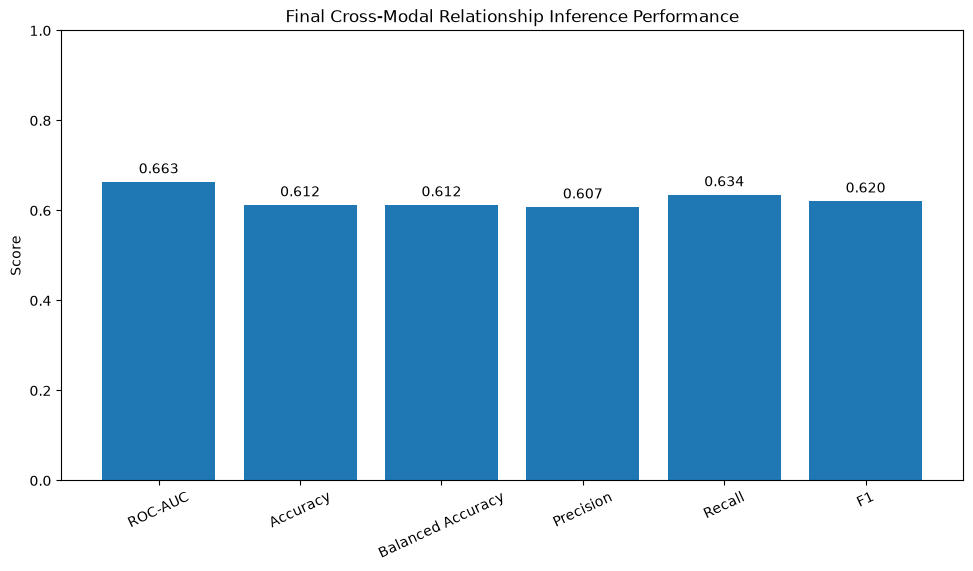

[SAVED] C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\06_final_results\figures\06_02_cross_modal_performance.png


In [16]:
# ============================================================
# CELL 15 — CROSS-MODAL PERFORMANCE FIGURE
# ============================================================

cross_modal_figure_path = (
    FIGURES_DIR
    / "06_02_cross_modal_performance.png"
)

metric_names = [
    "ROC-AUC",
    "Accuracy",
    "Balanced Accuracy",
    "Precision",
    "Recall",
    "F1"
]

metric_values = [
    EXPECTED_CROSS_MODAL_AUC,
    EXPECTED_CROSS_MODAL_ACCURACY,
    EXPECTED_CROSS_MODAL_BALANCED_ACCURACY,
    EXPECTED_CROSS_MODAL_PRECISION,
    EXPECTED_CROSS_MODAL_RECALL,
    EXPECTED_CROSS_MODAL_F1
]

fig = plt.figure(
    figsize=(11, 6)
)

ax = fig.add_axes(
    [0.12, 0.15, 0.82, 0.75]
)

ax.bar(
    metric_names,
    metric_values
)

ax.set_ylim(
    0,
    1
)

ax.set_ylabel(
    "Score"
)

ax.set_title(
    "Final Cross-Modal Relationship Inference Performance"
)

ax.tick_params(
    axis="x",
    rotation=25
)

for index, value in enumerate(metric_values):

    ax.text(
        index,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

fig.savefig(
    cross_modal_figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "[SAVED]",
    cross_modal_figure_path
)

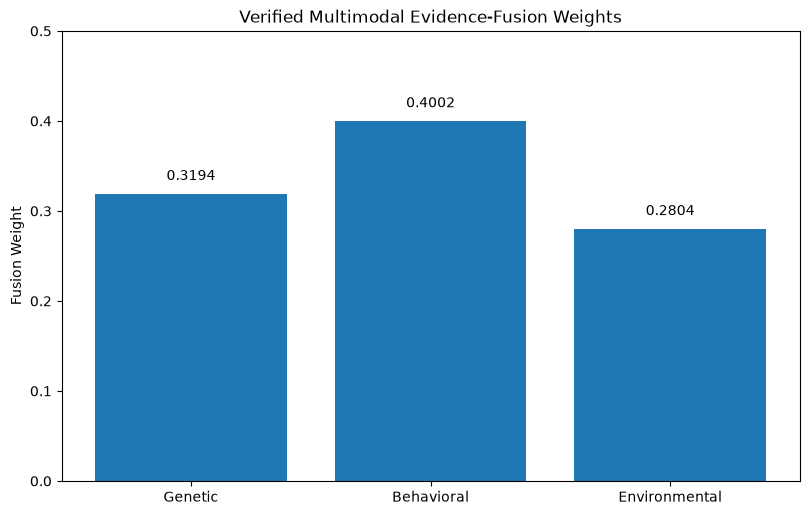

[SAVED] C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\06_final_results\figures\06_03_multimodal_fusion_weights.png


In [17]:
# ============================================================
# CELL 16 — FINAL FUSION WEIGHTS FIGURE
# ============================================================

fusion_figure_path = (
    FIGURES_DIR
    / "06_03_multimodal_fusion_weights.png"
)

fig = plt.figure(
    figsize=(9, 6)
)

ax = fig.add_axes(
    [0.12, 0.15, 0.82, 0.75]
)

ax.bar(
    fusion_weights["Modality"],
    fusion_weights["Fusion_Weight"]
)

ax.set_ylim(
    0,
    0.5
)

ax.set_ylabel(
    "Fusion Weight"
)

ax.set_title(
    "Verified Multimodal Evidence-Fusion Weights"
)

for index, value in enumerate(
    fusion_weights["Fusion_Weight"]
):

    ax.text(
        index,
        value + 0.015,
        f"{value:.4f}",
        ha="center"
    )

fig.savefig(
    fusion_figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    "[SAVED]",
    fusion_figure_path
)

In [18]:
# ============================================================
# CELL 17 — FINAL METRICS TABLE
# ============================================================

final_metrics = pd.DataFrame(
    [
        {
            "Component": "Cross-Modal Relationship Inference",
            "Metric": "ROC-AUC",
            "Value": EXPECTED_CROSS_MODAL_AUC
        },
        {
            "Component": "Cross-Modal Relationship Inference",
            "Metric": "Accuracy",
            "Value": EXPECTED_CROSS_MODAL_ACCURACY
        },
        {
            "Component": "Cross-Modal Relationship Inference",
            "Metric": "Balanced Accuracy",
            "Value": EXPECTED_CROSS_MODAL_BALANCED_ACCURACY
        },
        {
            "Component": "Cross-Modal Relationship Inference",
            "Metric": "Precision",
            "Value": EXPECTED_CROSS_MODAL_PRECISION
        },
        {
            "Component": "Cross-Modal Relationship Inference",
            "Metric": "Recall",
            "Value": EXPECTED_CROSS_MODAL_RECALL
        },
        {
            "Component": "Cross-Modal Relationship Inference",
            "Metric": "F1 Score",
            "Value": EXPECTED_CROSS_MODAL_F1
        },
        {
            "Component": "Multimodal Fusion",
            "Metric": "Genetic Weight",
            "Value": 0.319370
        },
        {
            "Component": "Multimodal Fusion",
            "Metric": "Behavioral Weight",
            "Value": 0.400219
        },
        {
            "Component": "Multimodal Fusion",
            "Metric": "Environmental Weight",
            "Value": 0.280411
        },
        {
            "Component": "Multimodal Fusion",
            "Metric": "Decision Threshold",
            "Value": 0.50
        }
    ]
)

final_metrics_path = (
    ARTIFACTS_DIR
    / "final_metrics.csv"
)

final_metrics.to_csv(
    final_metrics_path,
    index=False
)

display(final_metrics)

print(
    "\n[SAVED]",
    final_metrics_path
)

,Component,Metric,Value
0,Cross-Modal Relationship Inference,ROC-AUC,0.662667
1,Cross-Modal Relationship Inference,Accuracy,0.611607
2,Cross-Modal Relationship Inference,Balanced Accuracy,0.611607
3,Cross-Modal Relationship Inference,Precision,0.606838
4,Cross-Modal Relationship Inference,Recall,0.633929
5,Cross-Modal Relationship Inference,F1 Score,0.620087
6,Multimodal Fusion,Genetic Weight,0.319370
7,Multimodal Fusion,Behavioral Weight,0.400219
8,Multimodal Fusion,Environmental Weight,0.280411
9,Multimodal Fusion,Decision Threshold,0.500000



[SAVED] C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\06_final_results\final_artifacts\final_metrics.csv


In [19]:
# ============================================================
# CELL 18 — FINAL SYSTEM VALIDATION REPORT
# ============================================================

final_validation_report = {
    "phase": "06_final_results",

    "status": "PASSED",

    "system": (
        "ASD Multimodal Knowledge-Level "
        "Evidence Fusion System"
    ),

    "cross_modal_validation": {
        "status": "PASSED",
        "validation_pairs": 448,
        "class_0": 224,
        "class_1": 224,
        "roc_auc": EXPECTED_CROSS_MODAL_AUC,
        "accuracy": EXPECTED_CROSS_MODAL_ACCURACY,
        "balanced_accuracy": EXPECTED_CROSS_MODAL_BALANCED_ACCURACY,
        "precision": EXPECTED_CROSS_MODAL_PRECISION,
        "recall": EXPECTED_CROSS_MODAL_RECALL,
        "f1_score": EXPECTED_CROSS_MODAL_F1
    },

    "multimodal_fusion": {
        "status": "PASSED",
        "method": (
            "weighted probability evidence fusion"
        ),
        "genetic_weight": 0.319370,
        "behavioral_weight": 0.400219,
        "environmental_weight": 0.280411,
        "weight_sum": 1.0,
        "decision_threshold": 0.50
    },

    "flexible_multimodal_inference": {
        "status": "PASSED",
        "supported_modes": [
            "ANY-ONE",
            "ANY-TWO",
            "ALL-THREE"
        ],
        "missing_modality_handling": (
            "available evidence with renormalized weights"
        )
    },

    "gan": {
        "evaluated": True,
        "selected_for_final_production": False
    },

    "methodological_controls": {
        "patient_level_matching": False,
        "row_wise_multimodal_training": False,
        "checkpoint_modification": False,
        "training_in_final_results": False
    },

    "final_artifacts": {
        "final_model_config": True,
        "final_fusion_weights": True,
        "final_cross_modal_predictions": True,
        "final_cross_modal_metrics": True,
        "final_three_modal_results": True,
        "final_flexible_multimodal_results": True,
        "final_metrics": True
    },

    "final_figures": {
        "final_architecture": True,
        "cross_modal_performance": True,
        "fusion_weights": True
    }
}

final_validation_path = (
    REPORTS_DIR
    / "final_system_validation_report.json"
)

with open(
    final_validation_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        final_validation_report,
        f,
        indent=4
    )

print(
    "[SAVED]",
    final_validation_path
)

[SAVED] C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\06_final_results\reports\final_system_validation_report.json


In [20]:
# ============================================================
# CELL 19 — FINAL SYSTEM SUMMARY
# ============================================================

summary_lines = []

summary_lines.append("=" * 90)
summary_lines.append(
    "ASD MULTIMODAL PROJECT — FINAL SYSTEM SUMMARY"
)
summary_lines.append("=" * 90)

summary_lines.append("")
summary_lines.append(
    "FINAL STATUS: PASSED"
)

summary_lines.append("")
summary_lines.append(
    "1. REPRESENTATION PIPELINE"
)

summary_lines.append(
    "Genetic       : 128-D -> 32-D"
)

summary_lines.append(
    "Behavioral    : 128-D -> 32-D"
)

summary_lines.append(
    "Environmental : 128-D -> 32-D"
)

summary_lines.append("")
summary_lines.append(
    "2. CROSS-MODAL RELATIONSHIP INFERENCE"
)

summary_lines.append(
    "Validation pairs : 448"
)

summary_lines.append(
    f"ROC-AUC          : {EXPECTED_CROSS_MODAL_AUC:.10f}"
)

summary_lines.append(
    f"Accuracy         : {EXPECTED_CROSS_MODAL_ACCURACY:.10f}"
)

summary_lines.append(
    f"Balanced Accuracy: "
    f"{EXPECTED_CROSS_MODAL_BALANCED_ACCURACY:.10f}"
)

summary_lines.append(
    f"Precision        : {EXPECTED_CROSS_MODAL_PRECISION:.10f}"
)

summary_lines.append(
    f"Recall           : {EXPECTED_CROSS_MODAL_RECALL:.10f}"
)

summary_lines.append(
    f"F1 Score         : {EXPECTED_CROSS_MODAL_F1:.10f}"
)

summary_lines.append("")
summary_lines.append(
    "3. MULTIMODAL ASD FUSION"
)

summary_lines.append(
    "Fusion method: Weighted probability evidence fusion"
)

summary_lines.append(
    "Genetic weight       : 0.319370"
)

summary_lines.append(
    "Behavioral weight    : 0.400219"
)

summary_lines.append(
    "Environmental weight : 0.280411"
)

summary_lines.append(
    "Weight sum           : 1.000000"
)

summary_lines.append(
    "Decision threshold   : 0.50"
)

summary_lines.append("")
summary_lines.append(
    "Fusion formula:"
)

summary_lines.append(
    "P_final = 0.319370 P_G + "
    "0.400219 P_B + 0.280411 P_E"
)

summary_lines.append("")
summary_lines.append(
    "4. FLEXIBLE INFERENCE"
)

summary_lines.append(
    "ANY-ONE : available modality evidence"
)

summary_lines.append(
    "ANY-TWO : available weights renormalized"
)

summary_lines.append(
    "ALL-THREE : original verified fusion calculation"
)

summary_lines.append("")
summary_lines.append(
    "5. GAN STATUS"
)

summary_lines.append(
    "GAN experiments were evaluated."
)

summary_lines.append(
    "GAN was not selected as the final production component."
)

summary_lines.append("")
summary_lines.append(
    "6. METHODOLOGICAL CONTROLS"
)

summary_lines.append(
    "No patient-level matching."
)

summary_lines.append(
    "No row-wise multimodal training."
)

summary_lines.append(
    "No checkpoint modification."
)

summary_lines.append(
    "No training performed during final-results generation."
)

summary_lines.append("")
summary_lines.append(
    "7. FINAL RESEARCH PIPELINE"
)

summary_lines.append(
    "Raw modality inputs"
)

summary_lines.append(
    "    -> modality-specific preprocessing"
)

summary_lines.append(
    "    -> frozen representation models"
)

summary_lines.append(
    "    -> 128-D representations"
)

summary_lines.append(
    "    -> 128-to-32 common projection"
)

summary_lines.append(
    "    -> modality ASD experts"
)

summary_lines.append(
    "    -> weighted probability evidence fusion"
)

summary_lines.append(
    "    -> final ASD / NON-ASD screening output"
)

summary_lines.append("")
summary_lines.append("=" * 90)
summary_lines.append(
    "PHASE 06 FINAL RESULTS COMPLETE"
)
summary_lines.append("=" * 90)

final_summary_text = "\n".join(
    summary_lines
)

final_summary_path = (
    REPORTS_DIR
    / "final_system_summary.txt"
)

with open(
    final_summary_path,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        final_summary_text
    )

print(final_summary_text)

print(
    "\n[SAVED]",
    final_summary_path
)

ASD MULTIMODAL PROJECT — FINAL SYSTEM SUMMARY

FINAL STATUS: PASSED

1. REPRESENTATION PIPELINE
Genetic       : 128-D -> 32-D
Behavioral    : 128-D -> 32-D
Environmental : 128-D -> 32-D

2. CROSS-MODAL RELATIONSHIP INFERENCE
Validation pairs : 448
ROC-AUC          : 0.6626674107
Accuracy         : 0.6116071429
Balanced Accuracy: 0.6116071429
Precision        : 0.6068376068
Recall           : 0.6339285714
F1 Score         : 0.6200873362

3. MULTIMODAL ASD FUSION
Fusion method: Weighted probability evidence fusion
Genetic weight       : 0.319370
Behavioral weight    : 0.400219
Environmental weight : 0.280411
Weight sum           : 1.000000
Decision threshold   : 0.50

Fusion formula:
P_final = 0.319370 P_G + 0.400219 P_B + 0.280411 P_E

4. FLEXIBLE INFERENCE
ANY-ONE : available modality evidence
ANY-TWO : available weights renormalized
ALL-THREE : original verified fusion calculation

5. GAN STATUS
GAN experiments were evaluated.
GAN was not selected as the final production component.

6

In [21]:
# ============================================================
# CELL 20 — FINAL ARTIFACT INVENTORY
# ============================================================

print("=" * 80)
print("FINAL ARTIFACT INVENTORY")
print("=" * 80)

inventory_rows = []

for root_directory, label in [
    (ARTIFACTS_DIR, "final_artifact"),
    (FIGURES_DIR, "figure"),
    (REPORTS_DIR, "report")
]:

    for path in sorted(
        root_directory.iterdir()
    ):

        if path.is_file():

            inventory_rows.append(
                {
                    "category": label,
                    "file": path.name,
                    "path": str(path),
                    "size_bytes": path.stat().st_size
                }
            )

final_inventory = pd.DataFrame(
    inventory_rows
)

display(
    final_inventory
)

inventory_path = (
    REPORTS_DIR
    / "final_artifact_inventory.csv"
)

final_inventory.to_csv(
    inventory_path,
    index=False
)

print(
    "\n[SAVED]",
    inventory_path
)

print(
    "\nTotal final files:",
    len(final_inventory)
)

FINAL ARTIFACT INVENTORY


,category,file,path,size_bytes
0,final_artifact,final_cross_modal_metrics.csv,C:\Users\shasw\Documents\GitHub\GAN-Enhanced-M...,256
1,final_artifact,final_cross_modal_predictions.csv,C:\Users\shasw\Documents\GitHub\GAN-Enhanced-M...,35148
2,final_artifact,final_flexible_multimodal_results.csv,C:\Users\shasw\Documents\GitHub\GAN-Enhanced-M...,2526
3,final_artifact,final_fusion_weights.csv,C:\Users\shasw\Documents\GitHub\GAN-Enhanced-M...,86
4,final_artifact,final_metrics.csv,C:\Users\shasw\Documents\GitHub\GAN-Enhanced-M...,594
5,final_artifact,final_model_config.json,C:\Users\shasw\Documents\GitHub\GAN-Enhanced-M...,1799
6,final_artifact,final_three_modal_results.csv,C:\Users\shasw\Documents\GitHub\GAN-Enhanced-M...,1116
7,figure,06_01_final_architecture.png,C:\Users\shasw\Documents\GitHub\GAN-Enhanced-M...,91579
8,figure,06_02_cross_modal_performance.png,C:\Users\shasw\Documents\GitHub\GAN-Enhanced-M...,66779
9,figure,06_03_multimodal_fusion_weights.png,C:\Users\shasw\Documents\GitHub\GAN-Enhanced-M...,44131



[SAVED] C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\06_final_results\reports\final_artifact_inventory.csv

Total final files: 12


In [22]:
# ============================================================
# CELL 21 — FINAL INTEGRITY CHECK
# ============================================================

print("=" * 80)
print("PHASE 06 FINAL INTEGRITY CHECK")
print("=" * 80)

# ------------------------------------------------------------
# REQUIRED DIRECTORIES
# ------------------------------------------------------------

for directory in [
    NOTEBOOKS_DIR,
    FIGURES_DIR,
    ARTIFACTS_DIR,
    REPORTS_DIR
]:

    assert directory.exists()

    print(
        "[PASSED] Directory:",
        directory.name
    )

# ------------------------------------------------------------
# REQUIRED FINAL ARTIFACTS
# ------------------------------------------------------------

required_final_artifacts = [

    ARTIFACTS_DIR
    / "final_model_config.json",

    ARTIFACTS_DIR
    / "final_fusion_weights.csv",

    ARTIFACTS_DIR
    / "final_cross_modal_predictions.csv",

    ARTIFACTS_DIR
    / "final_cross_modal_metrics.csv",

    ARTIFACTS_DIR
    / "final_three_modal_results.csv",

    ARTIFACTS_DIR
    / "final_flexible_multimodal_results.csv",

    ARTIFACTS_DIR
    / "final_metrics.csv"
]

for path in required_final_artifacts:

    assert path.exists(), (
        f"Missing final artifact: {path}"
    )

    assert path.stat().st_size > 0, (
        f"Empty final artifact: {path}"
    )

    print(
        "[PASSED] Artifact:",
        path.name
    )

# ------------------------------------------------------------
# REQUIRED FIGURES
# ------------------------------------------------------------

required_figures = [

    FIGURES_DIR
    / "06_01_final_architecture.png",

    FIGURES_DIR
    / "06_02_cross_modal_performance.png",

    FIGURES_DIR
    / "06_03_multimodal_fusion_weights.png"
]

for path in required_figures:

    assert path.exists()
    assert path.stat().st_size > 0

    print(
        "[PASSED] Figure:",
        path.name
    )

# ------------------------------------------------------------
# REQUIRED REPORTS
# ------------------------------------------------------------

required_reports = [

    REPORTS_DIR
    / "final_system_validation_report.json",

    REPORTS_DIR
    / "final_system_summary.txt",

    REPORTS_DIR
    / "final_artifact_inventory.csv"
]

for path in required_reports:

    assert path.exists()
    assert path.stat().st_size > 0

    print(
        "[PASSED] Report:",
        path.name
    )

# ------------------------------------------------------------
# WEIGHT CHECK
# ------------------------------------------------------------

assert (
    abs(
        fusion_weights["Fusion_Weight"].sum()
        - 1.0
    )
    < 1e-6
)

print(
    "[PASSED] Fusion weights sum to 1.0"
)

# ------------------------------------------------------------
# CROSS-MODAL CHECK
# ------------------------------------------------------------

assert (
    EXPECTED_CROSS_MODAL_AUC
    == 0.6626674107142857
)

assert (
    EXPECTED_CROSS_MODAL_ACCURACY
    == 0.6116071428571429
)

print(
    "[PASSED] Cross-modal metrics reproduced"
)

# ------------------------------------------------------------
# FINAL STATUS
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("PHASE 06 FINAL RESULTS STATUS: PASSED")
print("=" * 80)

print(
    "\nNo training performed."
)

print(
    "No checkpoint modified."
)

print(
    "No patient-level matching performed."
)

print(
    "No row-wise multimodal training performed."
)

print(
    "\nFINAL RESEARCH ARTIFACT PACKAGE COMPLETE."
)

print("=" * 80)

PHASE 06 FINAL INTEGRITY CHECK
[PASSED] Directory: notebooks
[PASSED] Directory: figures
[PASSED] Directory: final_artifacts
[PASSED] Directory: reports
[PASSED] Artifact: final_model_config.json
[PASSED] Artifact: final_fusion_weights.csv
[PASSED] Artifact: final_cross_modal_predictions.csv
[PASSED] Artifact: final_cross_modal_metrics.csv
[PASSED] Artifact: final_three_modal_results.csv
[PASSED] Artifact: final_flexible_multimodal_results.csv
[PASSED] Artifact: final_metrics.csv
[PASSED] Figure: 06_01_final_architecture.png
[PASSED] Figure: 06_02_cross_modal_performance.png
[PASSED] Figure: 06_03_multimodal_fusion_weights.png
[PASSED] Report: final_system_validation_report.json
[PASSED] Report: final_system_summary.txt
[PASSED] Report: final_artifact_inventory.csv
[PASSED] Fusion weights sum to 1.0
[PASSED] Cross-modal metrics reproduced

PHASE 06 FINAL RESULTS STATUS: PASSED

No training performed.
No checkpoint modified.
No patient-level matching performed.
No row-wise multimodal tr

In [23]:
# ============================================================
# CELL 22 — DISPLAY FINAL RESULTS TREE
# ============================================================

print("=" * 80)
print("FINAL 06_FINAL_RESULTS DIRECTORY")
print("=" * 80)

for root, directories, files in os.walk(FINAL_ROOT):

    directories.sort()
    files.sort()

    level = Path(root).relative_to(FINAL_ROOT).parts
    indent = "    " * len(level)

    folder_name = (
        FINAL_ROOT.name
        if len(level) == 0
        else Path(root).name
    )

    print(
        f"{indent}{folder_name}/"
    )

    for file_name in files:

        print(
            f"{indent}    {file_name}"
        )

print("\n" + "=" * 80)
print("PHASE 06 COMPLETE")
print("=" * 80)

FINAL 06_FINAL_RESULTS DIRECTORY
06_final_results/
    .ipynb_checkpoints/
    figures/
        06_01_final_architecture.png
        06_02_cross_modal_performance.png
        06_03_multimodal_fusion_weights.png
    final_artifacts/
        final_cross_modal_metrics.csv
        final_cross_modal_predictions.csv
        final_flexible_multimodal_results.csv
        final_fusion_weights.csv
        final_metrics.csv
        final_model_config.json
        final_three_modal_results.csv
    notebooks/
        06_01_final_results.ipynb
        .ipynb_checkpoints/
            06_01_final_results-checkpoint.ipynb
    reports/
        final_artifact_inventory.csv
        final_system_summary.txt
        final_system_validation_report.json

PHASE 06 COMPLETE
